# 06 · Robustness and explainability

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
from src.utils.config import path
T = path('results') / 'tables'
import pickle
res = pickle.load(open(path('results')/'analysis'/'analysis.pkl','rb'))

In [2]:
print('PBO', res['pbo']); print('DSR', res['dsr']); print({k: v for k, v in res['placebo'].items() if not hasattr(v, '__len__')}); print('shuffled labels', res['shuffled_label'])

PBO {'pbo': 0.8801087801087801, 'n_splits': 12870, 'n_strategies': 20, 'logit_median': -1.4469189829363254}
DSR {'sr0_monthly': 0.1996623081376401, 'n_trials': 99, 'dsr': 0.10835617271349646}
{'real_sharpe': np.float64(0.6967695098371938), 'null_sharpe_mean': np.float64(0.0318881114797276), 'null_sharpe_p95': np.float64(0.6428687183967482), 'p_value_sharpe': 0.042, 'real_ic': np.float64(0.041191803160719166), 'null_ic_p95': np.float64(0.005336587495184718), 'p_value_ic': 0.0, 'n_draws': 500}
shuffled labels {'ic_mean': np.float64(0.007320258301368795), 'ic_std': np.float64(0.048377394206790506), 'ic_ir': np.float64(0.5241728915080299), 'ic_t_nw': 1.3683725813376713, 'ic_pos_months': 0.59375, 'n_months': 96, 'oos_r2_rank': 1.83976101683081e-05, 'hit_rate': 0.5016851963366079}


In [3]:
res['size_buckets'].round(4)

,bucket,ls_q5_ew_ann,sharpe,t_mean,ic_mean,names_per_month
0,small,0.1266,0.9725,3.0242,0.0510,386.3542
1,mid,0.0352,0.2892,0.7972,0.0264,385.9896
2,large,0.0689,0.6911,1.7172,0.0282,386.6458


In [4]:
res['industry_ic'].round(4)

,ff12,ic_mean,ic_t,names_per_month
0,1,0.0097,0.6411,65.7917
1,2,0.0405,2.0497,43.8646
2,3,0.0388,3.2296,173.8646
3,4,0.0002,0.0063,42.6042
4,5,0.0245,1.2108,52.3646
5,6,0.0400,3.1361,206.2917
6,7,0.0317,1.3542,20.1354
7,9,0.0215,1.7377,146.0208
8,10,0.0537,3.4939,196.8125
9,12,0.0360,2.9952,211.1667


In [5]:
res['alt_lags'].round(4)

,variant,ic_mean,ic_std,ic_ir,ic_t_nw,ic_pos_months,n_months,oos_r2_rank,hit_rate
0,mkt_lag0,0.0428,0.0953,1.5566,4.3210,0.6875,96,0.0024,0.5159
1,mkt_lag2,0.0400,0.0999,1.3866,3.7834,0.6562,96,0.0023,0.5133
2,risk_lag10bd,0.0412,0.1006,1.4177,3.6346,0.6875,96,0.0025,0.5154


In [6]:
sh = res['shap']; print(sh['groups'].round(5)); sh['importance'].head(20).round(5)

group
marketing       0.01593
controls        0.01372
risk            0.00646
interactions    0.00108
Name: mean_abs_shap, dtype: float64


,feature,mean_abs_shap,group
3,r_rev_1,0.00418,controls
4,r_vol_12,0.00261,controls
47,r_mkt_capab,0.00223,marketing
59,r_zca_implementation,0.00216,marketing
57,r_zca_info_management,0.00175,marketing
6,r_illiq_12,0.00165,controls
9,r_gp,0.00141,controls
53,r_zca_profit_focus,0.00141,marketing
66,r_zca_end_user,0.00137,marketing
5,r_beta_36,0.00084,controls


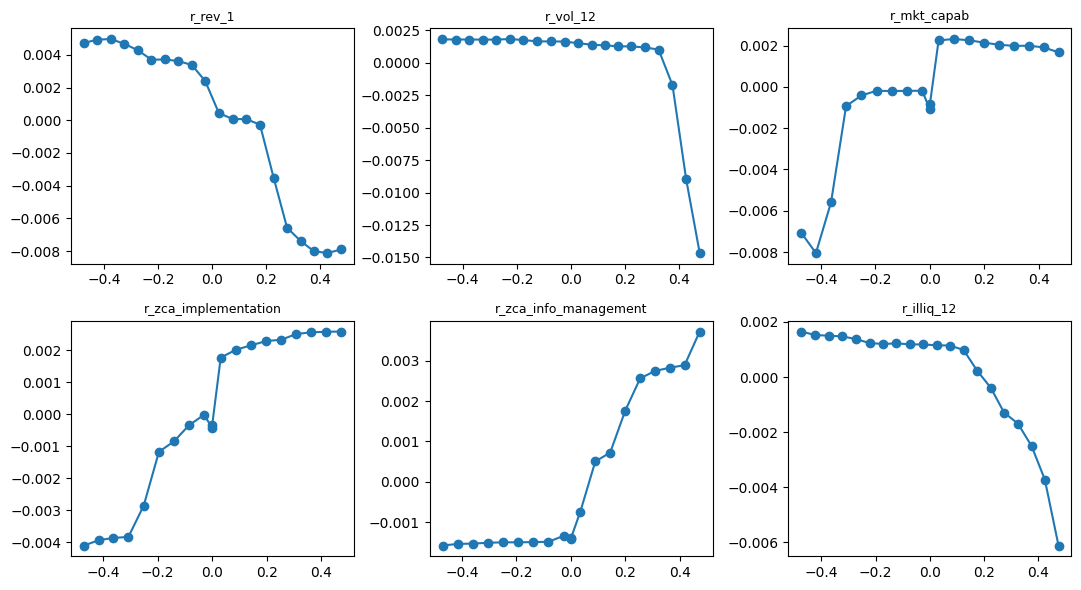

In [7]:
fig, axs = plt.subplots(2, 3, figsize=(11,6))
for ax, (f, d) in zip(axs.flat, sh['dependence'].items()): ax.plot(d['x'], d['shap'], marker='o'); ax.set_title(f, fontsize=9)
plt.tight_layout(); plt.show()